# CarFair-TN : exploration des données brutes

**Objectif du projet** : estimer le juste prix d'une voiture d'occasion en Tunisie à partir de ses caractéristiques
(marque, modèle, année, kilométrage, motorisation…). Les données proviennent de **[tayara.tn](https://www.tayara.tn)**,
principal site de petites annonces du pays : 7 178 annonces de la catégorie « voitures », collectées par scraping fin 2025.

**Rôle de ce notebook** : comprendre les données **avant toute transformation**. Sur une marketplace, chaque vendeur
remplit les champs comme il le souhaite : avant d'entraîner un modèle, il faut savoir ce que contient réellement
chaque colonne, ce qui est fiable et ce qui ne l'est pas.

**Démarche** : on part d'une vue d'ensemble, puis on examine chaque variable en commençant par la plus importante, le
prix, que le modèle devra prédire. Chaque section pose une question, l'explore, et se termine par ce qu'on en retient.

1. Vue d'ensemble
2. Le prix
3. Le kilométrage
4. Les autres variables numériques
5. Les variables catégorielles
6. Les doublons
7. Les annonces hors sujet

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

C1, C2 = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})

## 1. Vue d'ensemble

Chaque annonce comporte les champs structurés du site (prix, kilométrage, année, marque, modèle, cylindrée, puissance
fiscale, boîte, carburant, carrosserie, couleur, état), un titre et une description libres, un identifiant d'annonce, la ville
et la date de publication.

> **Données publiées anonymisées.** Les numéros de téléphone présents dans les annonces (titres, descriptions, et
> champs où certains vendeurs les saisissent) ont été remplacés par des numéros fictifs de même format : 8 chiffres,
> même premier chiffre. L'url de chaque annonce est remplacée par un identifiant anonyme (`id_annonce`). Ces
> modifications ne changent pas les phénomènes étudiés ici (`scripts/anonymize_raw_data.py`).

In [2]:
df = pd.read_csv(RAW_DIR / "tayara_cars_all_pages.csv")
print("Dimensions :", df.shape)
df.head()

Dimensions : (7178, 17)


,titre,prix,kilometrage,couleur_du_vehicule,etat_du_vehicule,boite,annee,cylindree,marque,modele,puissance_fiscale,type_de_carrosserie,carburant,description,id_annonce,location,posting_time
0,"Suzuki Celerio, première main",31000.0,53000,Bleu,NaN,Manuelle,2019.0,NaN,Suzuki,Celerio,4.0,Compacte,Essence,"Suzuki Celerio à vendre première main, Faible kilométrag...",2301135cc18a,tunis,"12:53, 30/11/2025"
1,Toyota Corolla Dynamic – 2021 – 49 900 km – Excellent état,73000.0,49900,Noir,Avec kilométrage,Automatique,2021.0,1.2L,Toyota,Corolla verso,6.0,Compacte,Essence,Je vends ma Toyota Corolla Hatchback – finition Dynamic ...,fce25973a859,Ariana,"13:53, 28/11/2025"
2,BMW Série 3 F30 316i 2014,NaN,170,Blanc,Nouveau,Manuelle,2014.0,1.6L,BMW,Serie 3 GT,7.0,Berline,Essence,Je mets en vente ma BMW F30 316i (2014) Essence 1.6 - 7 ...,f3113feb9f8a,Ariana,"13:53, 27/11/2025"
3,Bmw F30,52500.0,170,Blanc,Avec kilométrage,Manuelle,2014.0,1.6L,BMW,Serie 3,7.0,Berline,Essence,À VENDRE : BMW F30 316i – 2014 (Sport Line) Essence 1.6 ...,10541129f79f,Ariana,"13:53, 27/11/2025"
4,voiture Peugeot 3008 à vendre,1111.0,2202021,Bleu,Avec kilométrage,Automatique,2021.0,1.2L,Peugeot,3008,7.0,Autres,Essence,"particulier ,je mets une très belle Peugeot 3008 à vendr...",b306aa9e1443,Nabeul,"13:53, 27/11/2025"


In [3]:
df.dtypes.to_frame("type").T

,titre,prix,kilometrage,couleur_du_vehicule,etat_du_vehicule,boite,annee,cylindree,marque,modele,puissance_fiscale,type_de_carrosserie,carburant,description,id_annonce,location,posting_time
type,object,float64,object,object,object,object,float64,object,object,object,float64,object,object,object,object,object,object


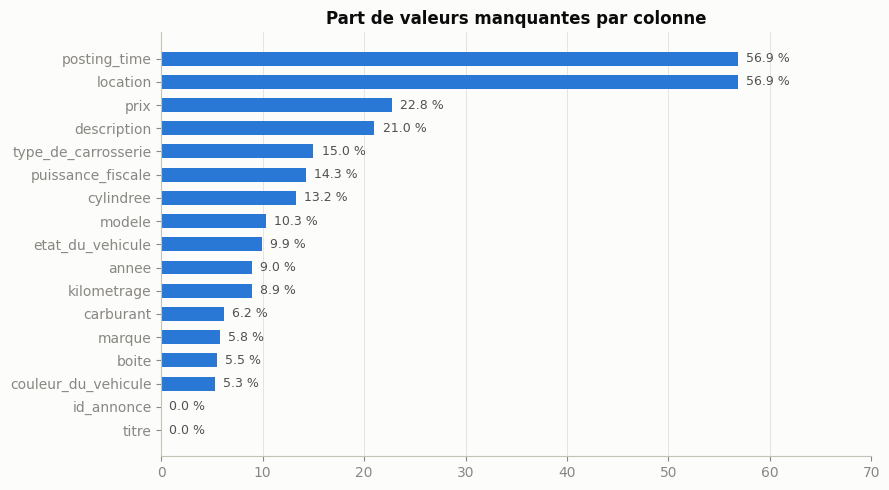

In [4]:
missing = df.isna().mean().mul(100).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(missing.index, missing.values, color=C1, height=0.6)
ax.set_axisbelow(True)
for y, v in enumerate(missing.values):
    ax.text(v + 0.8, y, f"{v:.1f} %", va="center", color="#52514e", fontsize=9)
ax.set_xlim(0, 70)
ax.grid(axis="y", visible=False)
ax.set_title("Part de valeurs manquantes par colonne")
plt.tight_layout()
plt.show()

**Constats**

- **Près d'une annonce sur quatre (22.8 %) n'a pas de prix.** C'est la variable à prédire : ces annonces ne pourront
  pas servir à l'entraînement, sauf si le prix se trouve ailleurs dans l'annonce.
- La ville et la date ne sont disponibles que pour 43 % des annonces.
- Les caractéristiques techniques (carrosserie, puissance fiscale, cylindrée, modèle) manquent dans 10 à 15 % des cas.
- Le kilométrage est stocké en texte (`object`) et non en nombre : il faudra regarder pourquoi.

Les valeurs manquantes ne sont qu'une partie du problème : une valeur présente peut aussi être fausse. Les statistiques
descriptives des colonnes numériques le montrent.

In [5]:
df[["prix", "annee", "puissance_fiscale"]].describe().T.style.format("{:,.1f}")

,count,mean,std,min,25%,50%,75%,max
prix,"5,543.0","822,368,302.8","46,779,136,925.7",0.0,"5,000.0","32,500.0","56,500.0","3,333,333,500,000.0"
annee,"6,533.0","2,017.6",246.4,0.0,"2,011.0","2,017.0","2,021.0","9,999.0"
puissance_fiscale,"6,154.0","180,551,213,982.1","14,163,766,045,149.4",0.0,5.0,6.0,8.0,"1,111,111,111,111,111.0"


**Constats**

Ces statistiques sont inexploitables en l'état :

- le **prix moyen** dépasse 800 millions de dinars, pour une médiane de 32 500 TND, et le maximum atteint 3 300 milliards ;
- l'**année** va de 0 à 9999 ;
- la **puissance fiscale** (normalement entre 3 et 20 CV environ) atteint 1.1 × 10¹⁵.

Quelques valeurs extrêmes suffisent à fausser complètement la moyenne. Il faut examiner chaque variable en détail pour
comprendre d'où elles viennent.

## 2. Le prix

Le prix est la variable que le modèle devra prédire : chaque erreur dans cette colonne sera apprise par le modèle. On
commence par regarder comment les valeurs se répartissent, par ordre de grandeur, avec l'année médiane des voitures de
chaque tranche.

In [6]:
price_bins = [0, 10, 100, 1_000, 5_000, 1_000_000, 1e7, np.inf]
price_labels = ["1 – 9", "10 – 99", "100 – 999", "1 000 – 4 999", "5 000 – 1 M", "1 M – 10 M", "> 10 M"]
price_band = pd.cut(df["prix"], price_bins, labels=price_labels, right=False)

overview = df.groupby(price_band, observed=False).agg(
    annonces=("prix", "size"),
    annee_mediane=("annee", "median"),
    prix_median=("prix", "median"),
)
overview.loc["manquant"] = [df["prix"].isna().sum(), df.loc[df["prix"].isna(), "annee"].median(), np.nan]
overview

,annonces,annee_mediane,prix_median
prix,,,
1 – 9,122.0,2012.5,5.0
10 – 99,853.0,2015.0,39.0
100 – 999,221.0,2020.0,123.0
1 000 – 4 999,187.0,2016.0,1234.0
5 000 – 1 M,3912.0,2017.0,40000.0
1 M – 10 M,18.0,2012.0,3899999.5
> 10 M,230.0,2019.0,55111110.0
manquant,1635.0,2018.0,NaN


**Constats**

- Seules 3 912 annonces (55 %) ont un prix dans une fourchette réaliste pour une voiture (5 000 TND à 1 million).
- **853 annonces affichent un prix entre 10 et 99 TND**, pour des voitures dont l'année médiane est 2015. Aucune voiture
  de 2015 ne vaut une quarantaine de dinars (prix médian de la tranche : 39) : ces valeurs ont un sens qu'il faut
  comprendre.
- 230 annonces dépassent 10 millions de TND, avec un prix médian de 55 111 110 : cette valeur précise semble se répéter.

Les valeurs les plus fréquentes du champ vont permettre d'y voir plus clair.

In [7]:
df["prix"].value_counts().head(20).rename("annonces").to_frame().T

prix,55111110.0,35000.0,5.0,45000.0,1234.0,25000.0,28000.0,55000.0,65000.0,30000.0,40000.0,123.0,27000.0,42000.0,37000.0,36000.0,32000.0,52000.0,43000.0,50000.0
annonces,131,81,72,69,68,63,63,57,55,54,54,53,49,49,48,48,46,46,44,44


**Constats**

Parmi les 20 prix les plus fréquents, quatre ne peuvent pas être de vrais prix :

- **55 111 110** est le prix le plus fréquent du site (131 annonces) ;
- **5** (72 annonces), **1234** (68) et **123** (53) sont des valeurs de remplissage.

Ce sont les annonces de vendeurs qui ne veulent pas afficher de prix et préfèrent le négocier par téléphone : la
valeur saisie ne porte aucune information.

### Les prix entre 10 et 999

Si ces valeurs ne sont pas des valeurs de remplissage, elles pourraient être des prix exprimés en **milliers de
dinars**, une écriture abrégée courante (« 45 » pour 45 000 TND). Voyons quelques exemples.

In [8]:
small = df[df["prix"].between(10, 999)]
small[["titre", "prix", "annee", "marque", "modele"]].sample(12, random_state=1)

,titre,prix,annee,marque,modele
4558,haval jolion,48.0,2024.0,Haval,jolion
3253,Audi fontome essence gaz a vendre,14.0,1992.0,Audi,80
530,Passat B8 Année 2013,46.0,2013.0,Volkswagen,Passat
1808,92950893 Chevrolet sonic tt option neuf 1er main,39.0,2022.0,Chevrolet,Aveo
6727,Peugeot 208,32.0,2014.0,Peugeot,208
829,toyota chr,83.0,2023.0,Toyota,NaN
2769,ranger,110.0,2018.0,Ford,Ranger
3919,nissan micra,25.0,2014.0,Nissan,Micra
2835,mahindra pik-up scorpio,34.0,2015.0,Mahindra,Scorpion
1714,Audi A3 en excellent état,74.0,2019.0,Audi,A3


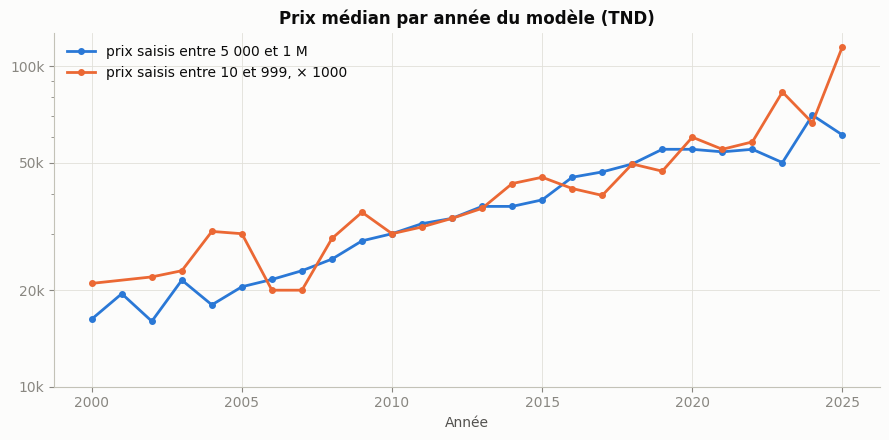

In [9]:
normal = df[df["prix"].between(5_000, 1_000_000)]
older = small[~small["prix"].isin([111, 123, 999])]

med_normal = normal.groupby("annee")["prix"].median().loc[2000:2025]
med_small = (older.groupby("annee")["prix"].median() * 1000).loc[2000:2025]
counts_small = older.groupby("annee").size().loc[2000:2025]
med_small = med_small[counts_small >= 5]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(med_normal.index, med_normal.values, color=C1, lw=2, marker="o", ms=4, label="prix saisis entre 5 000 et 1 M")
ax.plot(med_small.index, med_small.values, color=C2, lw=2, marker="o", ms=4, label="prix saisis entre 10 et 999, × 1000")
ax.set_yscale("log")
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks([10_000, 20_000, 50_000, 100_000], ["10k", "20k", "50k", "100k"])
ax.set_title("Prix médian par année du modèle (TND)")
ax.set_xlabel("Année")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Constats**

Les exemples sont cohérents avec des prix en milliers : une Golf 7 de 2017 à « 51 », une Audi A3 de 2019 à « 74 »,
une Nissan Micra de 2014 à « 25 ».

Le graphique le confirme sur l'ensemble des annonces : une fois multipliés par 1000, ces prix suivent la même évolution
par année que les prix saisis normalement. Si c'étaient des erreurs aléatoires, la courbe orange n'aurait aucune raison
de suivre la courbe bleue.

**Ces quelque 1 000 annonces ne sont donc pas inutilisables : leur prix est simplement exprimé dans une autre unité.**
Les supprimer reviendrait à perdre environ une annonce exploitable sur cinq.

### Les prix supérieurs à 1 million

En dehors de la valeur 55 111 110, que représentent les autres prix très élevés ? On regarde leur nombre de chiffres
et s'ils sont des multiples de 1000.

In [10]:
large = df[df["prix"] > 1_000_000].copy()
large["chiffres"] = large["prix"].astype("int64").astype(str)
large["nb_chiffres"] = large["chiffres"].str.len()
large["premier_chiffre"] = large["chiffres"].str[0]
large["multiple_de_1000"] = large["prix"] % 1000 == 0

print("Annonces à plus de 1 000 000 :", len(large))
print("dont 55 111 110 :", (large["prix"] == 55_111_110).sum())
others = large[large["prix"] != 55_111_110]
pd.crosstab(others["nb_chiffres"], others["multiple_de_1000"].map({True: "multiple de 1000", False: "non arrondi"}))

Annonces à plus de 1 000 000 : 248
dont 55 111 110 : 131


multiple_de_1000,multiple de 1000,non arrondi
nb_chiffres,,
7,9,9
8,35,50
9,2,5
10,0,2
11,1,0
12,2,0
13,2,0


In [11]:
eight = others[(others["nb_chiffres"] == 8) & ~others["multiple_de_1000"]]
print("Prix à 8 chiffres non arrondis, répartition du premier chiffre :")
display(eight["premier_chiffre"].value_counts().rename("annonces").to_frame().T)
eight[["titre", "prix", "annee", "marque", "modele"]].head(8)

Prix à 8 chiffres non arrondis, répartition du premier chiffre :


premier_chiffre,2,9,1,5
annonces,20,12,10,8


,titre,prix,annee,marque,modele
189,Peugeot 301,29703514.0,2019.0,Peugeot,301
249,PEUGEOT 2008 réparation MAISON UNIQUEMENT,91241453.0,2016.0,Peugeot,2008
343,peugeot expert,50884343.0,2000.0,Peugeot,Expert
590,Citroën c Elysee,96981682.0,2015.0,Citroen,C-Elysée
769,Peugeot 301 voiture de la famille,50340375.0,2019.0,Peugeot,301
919,Audi A4 1.4 TFSI,97419198.0,2018.0,Audi,A4
951,au meilleur prix proposé,11111109.0,2014.0,Citroen,Berlingo
1210,GOLF 6 GTI,59411192.0,2013.0,Volkswagen,Golf


**Constats**

La plupart des prix à 8 chiffres non arrondis commencent par **2, 5 ou 9**, comme les numéros de téléphone mobile
tunisiens, qui comptent justement 8 chiffres. Faute de pouvoir écrire son numéro ailleurs, le vendeur l'a saisi dans
le champ prix. Ceux qui commencent par 1 ressemblent plutôt à des valeurs de remplissage (`11 111 109`).

Ces valeurs ne contiennent aucune information de prix.

In [12]:
round_large = others[others["multiple_de_1000"] & (others["prix"] < 1e9)]
round_large[["titre", "prix", "annee", "marque", "modele"]].assign(prix_div_1000=lambda d: d["prix"] / 1000).head(10)

,titre,prix,annee,marque,modele,prix_div_1000
71,Renault Mégane,1200000.0,1999.0,Renault,Megane,1200.0
317,kia Rio,36000000.0,2017.0,Kia,Rio,36000.0
799,Kia rio,46000000.0,2029.0,Kia,Rio,46000.0
1201,vente mini cooper,27000000.0,2009.0,mini,Cooper,27000.0
1329,fiat punto,21000000.0,2007.0,Fiat,Punto,21000.0
1430,Toyota Aygo,25000000.0,2014.0,Toyota,Aygo,25000.0
1586,للبيع سيارة تيقوان في حالة جيدة,70000000.0,2011.0,Volkswagen,Tiguan,70000.0
1757,Ford ecosport diesel 94574281,44000000.0,2017.0,Ford,ECOSPORT,44000.0
2173,Passat b 7,31000000.0,2007.0,Volkswagen,Passat,31000.0
2580,Golf,6000000.0,2000.0,Volkswagen,Golf 2,6000.0


**Constats**

Les prix élevés **ronds** racontent une autre histoire : une Kia Rio de 2017 à 36 000 000, une Fiat Punto de 2007 à
21 000 000. Divisés par 1000, ils donnent des prix tout à fait plausibles (36 000 et 21 000 TND).

Le dinar tunisien se divise en 1 000 **millimes** : ces vendeurs ont saisi leur prix en millimes. On retrouve cette
écriture dans certaines descriptions (« PRIX 82,000,000TND » pour une Peugeot 2008 de 2020).

La division par 1000 n'est pas toujours correcte : une Renault Mégane de 1999 à 1 200 000 donnerait 1 200 TND, ce qui
est trop bas. Une conversion automatique devra donc être vérifiée en comparant le résultat au prix de voitures similaires.

In [13]:
mid = df[df["prix"].between(1_000, 4_999)]
print("Valeurs les plus fréquentes entre 1 000 et 4 999 :")
display(mid["prix"].value_counts().head(8).rename("annonces").to_frame().T)
mid[["titre", "prix", "annee", "marque", "modele"]].sample(10, random_state=0)

Valeurs les plus fréquentes entre 1 000 et 4 999 :


prix,1234.0,1111.0,1000.0,3500.0,1500.0,4500.0,2000.0,2500.0
annonces,68,31,16,8,6,6,4,3


,titre,prix,annee,marque,modele
4087,mouteur complet citroen c4 essence,1500.0,NaN,Citroen,C4
1776,404,4750.0,NaN,Peugeot,404
6472,Voitures,3100.0,NaN,NaN,NaN
2486,tayota yaris france,1234.0,2022.0,Toyota,Yaris
4592,Vente voiture Renault capture,1111.0,2014.0,Renault,Captur
3240,Peugeot 308,1234.0,2020.0,Peugeot,308
648,Glc300e kit AMG,1234.0,2021.0,Mercedes-Benz,Classe GLC
4164,voiture a vendre ferraille,3500.0,1990.0,Autres,Autres
6235,Voitures,4400.0,NaN,NaN,NaN
285,GLE 350 de kit AMG,1234.0,2021.0,Mercedes-Benz,Classe GLE


**Constats**

La tranche 1 000 – 4 999 TND est un mélange :

- des valeurs de remplissage (`1234` et `1111` représentent la moitié de la tranche), y compris pour des voitures
  récentes (Mercedes GLC de 2021 à 1234) ;
- des annonces qui ne sont pas des voitures (« mouteur complet citroen c4 » à 1 500) ;
- de vraies voitures en fin de vie (« voiture a vendre ferraille » de 1990 à 3 500).

Un seuil fixe ne peut pas séparer ces cas. Il faudra juger chaque prix par rapport à la voiture concernée.

In [14]:
no_price = df[df["prix"].isna()]
text = (no_price["titre"].fillna("") + " " + no_price["description"].fillna("")).str.lower()
mentions = text.str.contains(r"prix\s*:?\s*\d|\d[\d\s.,]*\s*(?:dt|tnd|dinars?|md)\b", regex=True)
print(f"Annonces sans prix : {len(no_price):,}")
print(f"dont avec un prix mentionné dans le titre ou la description : {mentions.sum():,}")
no_price.loc[mentions, "description"].str.slice(0, 160).head(5).tolist()

Annonces sans prix : 1,635
dont avec un prix mentionné dans le titre ou la description : 31


["Description 🇮🇹🇮🇹 FIAT PANDA 🐼 city 1ère main état d'origine 1.2 L 🇮🇹🇮🇹 💲 PRIX : 38800 négociable 🔴 CARACTÉRISTIQUES : ✅ Année : 2020 ✅ Kilométrage : 92mk ✅ CARR",
 '🌟PEUGEOT 2008 GT 🌟 📲|🔁 Possibilité de vente ou échange PRIX💰82,000,000TND💰 ➖ Motorisation Diesel 1.5 ➖ Immatriculation 248 ➖ Puissance Fiscale 7cv ➖ Modèle 2020',
 "Nous mettons en vente cette très belle Sportage en état presque Neuf. ✅ Voiture importée d'Allemagne ✅7ch Moteur 1.6 Diesel Hybride (136ch) ✅ Très puissante et ",
 '-HYUNDAI SOLARIS /ACCENT 1.4 -peinture et tous les vitres origines -Année 2017 - 4 cylindres -2éme main et 90.000 km - impeccable tôle et moteur -Fermeture cent',
 'KIA Picanto 2023 état neuf à vendre 4 vitres électriques Radar de recul ABS Airbag Climatiseur 4 pneus neufs KLM 99,000 2ème main Prix 38,000 TelLire plus']

**Constats**

Sur les 1 635 annonces sans prix, seules 31 mentionnent un prix dans le titre ou la description. La récupération par le
texte est possible mais marginale. Elle demandera de la prudence : les formats sont variés (« PRIX : 38800 »,
« 82,000,000TND », « Prix 38,000 »), et un nombre suivi de « km » n'est pas un prix.

**Bilan sur le prix.** Le champ prix mélange au moins six réalités différentes : de vrais prix en dinars, des prix en
milliers de dinars, des prix en millimes, des valeurs de remplissage, des numéros de téléphone et des prix d'objets qui ne
sont pas des voitures.

## 3. Le kilométrage

Le kilométrage est l'une des variables qui expliquent le mieux le prix d'une voiture d'occasion. Il est stocké en texte :
on commence par voir pourquoi, puis on examine sa distribution.

In [15]:
km_text = df["kilometrage"].dropna().astype(str)
print("Valeurs contenant autre chose que des chiffres :", km_text[km_text.str.contains(r"\D")].unique().tolist())

km = pd.to_numeric(df["kilometrage"].astype(str).str.replace(r"\D", "", regex=True), errors="coerce")
km.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("kilometrage").T.style.format("{:,.0f}")

Valeurs contenant autre chose que des chiffres : ['73 500', '35 000', '0 3', '92 000', '150 000', '43 000', '53 000']


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
kilometrage,"6,536","1,535,244,334,669","123,693,296,760,939",0,51,341,"92,000","177,000","320,000","1,111,111","10,000,000,000,000,000"


In [16]:
km_bins = [0, 1, 1_000, 10_000, 500_000, 1_000_000, np.inf]
km_labels = ["0", "1 – 999", "1 000 – 9 999", "10 000 – 499 999", "500 000 – 999 999", "≥ 1 000 000"]
km.groupby(pd.cut(km, km_bins, labels=km_labels, right=False), observed=False).size().rename("annonces").to_frame().T

kilometrage,0,1 – 999,1 000 – 9 999,10 000 – 499 999,500 000 – 999 999,≥ 1 000 000
annonces,196,1558,115,4543,54,70


**Constats**

- Le format texte vient de quelques valeurs écrites avec des espaces (« 73 500 ») : rien de grave.
- **1 558 annonces indiquent entre 1 et 999 km**, et 196 indiquent 0 km. Ce serait beaucoup de voitures quasi neuves
  pour un site d'occasion.
- 70 annonces dépassent 1 000 000 km, un kilométrage qu'aucune voiture n'atteint en pratique.

On retrouve la même question que pour le prix : ces petites valeurs sont-elles des kilométrages en milliers ? L'état
déclaré par le vendeur (« Nouveau » ou « Avec kilométrage ») pourrait aider à trancher.

In [17]:
km_band = pd.cut(km, [0, 1, 1_000, np.inf], labels=["0", "1 – 999", "≥ 1 000"], right=False)
pd.crosstab(df["etat_du_vehicule"].fillna("(manquant)"), km_band)

kilometrage,0,1 – 999,≥ 1 000
etat_du_vehicule,,,
(manquant),12,77,256
Avec kilométrage,112,977,3362
Non dédouanné,7,7,28
Nouveau,54,464,1054
Pièces manquantes,5,10,12
RS,6,23,70


In [18]:
new_low = df[(df["etat_du_vehicule"] == "Nouveau") & km.between(1, 999)]
print("Annonces « Nouveau » entre 1 et 999 km, répartition de l'année :")
display(new_low["annee"].describe()[["count", "min", "50%", "max"]].to_frame().T)
new_low[["titre", "kilometrage", "annee", "marque", "modele"]].sample(8, random_state=2)

Annonces « Nouveau » entre 1 et 999 km, répartition de l'année :


,count,min,50%,max
annee,453.0,1981.0,2017.0,2222.0


,titre,kilometrage,annee,marque,modele
3783,Suzuki Swift,91,2021.0,Suzuki,Swift
634,Citroen berlingo k9 premier main,70,2023.0,Citroen,Berlingo
6586,hyundai grand i10,181,2017.0,Hyundai,I 10
2734,skoda octavia,166,2016.0,Skoda,Octavia
1646,seat ateca,2,2019.0,Seat,Ibiza
1745,i10,130,2017.0,Hyundai,I 10
3082,partnair,291,2005.0,Peugeot,Partner
2137,c3 2011 4cylindre,226,2011.0,Citroen,C3


**Constats**

- 977 annonces déclarées « **Avec kilométrage** » (donc d'occasion) indiquent moins de 1 000 km.
- 464 annonces déclarées « **Nouveau** » indiquent entre 1 et 999 km, mais leur année médiane est 2017 : une Hyundai
  i10 de 2017 « nouvelle » avec 181 km, une Citroën C3 de 2011 avec 226 km.

L'état déclaré n'est donc **pas fiable** : de nombreux vendeurs choisissent « Nouveau » pour une voiture en bon état.
L'âge de la voiture est un indice bien plus solide : 181 km sur une voiture de 2017 est invraisemblable, alors que
181 000 km est banal.

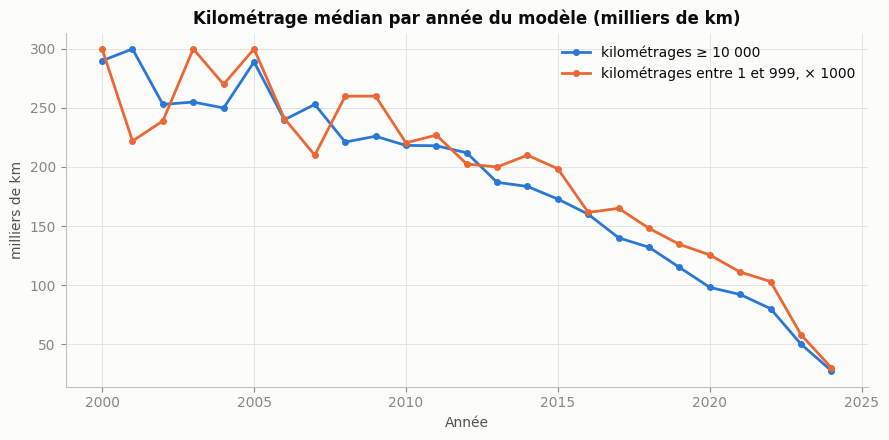

In [19]:
age = 2026 - df["annee"]
regular = km.where(km >= 10_000)
low_x1000 = (km.where(km.between(1, 999)) * 1000).where(age >= 2)

med_regular = regular.groupby(df["annee"]).median().loc[2000:2024]
med_low = low_x1000.groupby(df["annee"]).median().loc[2000:2024]
n_low = low_x1000.groupby(df["annee"]).count().loc[2000:2024]
med_low = med_low[n_low >= 5]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(med_regular.index, med_regular.values / 1000, color=C1, lw=2, marker="o", ms=4, label="kilométrages ≥ 10 000")
ax.plot(med_low.index, med_low.values / 1000, color=C2, lw=2, marker="o", ms=4, label="kilométrages entre 1 et 999, × 1000")
ax.set_title("Kilométrage médian par année du modèle (milliers de km)")
ax.set_xlabel("Année")
ax.set_ylabel("milliers de km")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Constats**

Pour les voitures de plus d'un an, les kilométrages entre 1 et 999, multipliés par 1000, suivent la même courbe que les
kilométrages saisis normalement. Comme pour le prix, **il s'agit de kilométrages exprimés en milliers** (« 181 » pour
181 000 km), et non de voitures neuves.

In [20]:
big = df.loc[km >= 1_000_000, ["titre", "kilometrage", "annee"]].copy()
big["finit_par_l_annee"] = [
    pd.notna(a) and str(k).replace(" ", "").endswith(str(int(a))) for k, a in zip(big["kilometrage"], big["annee"])
]
print("Kilométrages ≥ 1 000 000 :", len(big), "| dont se terminant par l'année de l'annonce :", big["finit_par_l_annee"].sum())
print("Autres valeurs :", big.loc[~big["finit_par_l_annee"], "kilometrage"].value_counts().head(20).to_dict())
big.sort_values("finit_par_l_annee", ascending=False).head(12)

Kilométrages ≥ 1 000 000 : 70 | dont se terminant par l'année de l'annonce : 11
Autres valeurs : {'1111111': 6, '2500000': 3, '111111111': 2, '3000000': 2, '9999999': 2, '97307395': 2, '2460000': 1, '1790000': 1, '1470000': 1, '1000000': 1, '122231233': 1, '1500000': 1, '2600000': 1, '1570000': 1, '4000050': 1, '95763496': 1, '3000002': 1, '11111111': 1, '1480000': 1, '11111111155': 1}


,titre,kilometrage,annee,finit_par_l_annee
4,voiture Peugeot 3008 à vendre,2202021,2021.0,True
2025,Mahindra kuv 100 k8 tel 56767153,1440002021,2021.0,True
4569,fiat bravo 1.4 essence,1250002008,2008.0,True
3263,a vendre peugeot 208 tbe,635002020,2020.0,True
4789,Haval H6,720002021,2021.0,True
2899,belle 3008 a vendre,2200002021,2021.0,True
2191,A Vendre 206 HDi,1000002009,2009.0,True
2154,peugeot 207,1900002009,2009.0,True
2691,superbe ds4 so chic,1450002015,2015.0,True
816,voiture Peugeot 3008 à vendre,2202021,2021.0,True


**Constats**

Une partie des kilométrages supérieurs à 1 million se termine **exactement par l'année de l'annonce** : `1440002021`
pour une Mahindra de 2021 correspond à 144 000 km suivis de 2021. Le kilométrage et l'année ont été collés lors de la
collecte des données. Les autres valeurs mélangent des valeurs de remplissage (`1111111`, `9999999`, `111111111`), des numéros de téléphone
(`97307395`, `95763496`) et des kilométrages probablement saisis avec un zéro de trop (`2500000`, `3000000`).

**Bilan sur le kilométrage.** Quatre défauts distincts : des valeurs en milliers, des valeurs collées à l'année, des
valeurs de remplissage et des numéros de téléphone. L'état déclaré « Nouveau » ne permet pas de les repérer.

## 4. Les autres variables numériques

L'année, la puissance fiscale et la cylindrée décrivent la voiture elle-même. Leurs plages de valeurs réalistes sont
connues : on vérifie si les données les respectent.

In [21]:
annee = df["annee"]
print("Années hors de [1980, 2026] :", int((~annee.between(1980, 2026) & annee.notna()).sum()))
display(annee[~annee.between(1980, 2026) & annee.notna()].value_counts().rename("annonces").to_frame().T)

pf = df["puissance_fiscale"]
print("\nPuissance fiscale, valeurs les plus fréquentes :")
display(pf.value_counts().head(12).rename("annonces").to_frame().T)
print("Puissance fiscale à 0 :", int((pf == 0).sum()), "| supérieure à 30 :", int((pf > 30).sum()))
display(pf[pf > 30].value_counts().head(10).rename("annonces").to_frame().T)

Années hors de [1980, 2026] : 53


annee,0.0,1220.0,1111.0,1979.0,1977.0,1974.0,2222.0,9999.0,9222.0,2043.0,9900.0,2102.0,2103.0,2051.0,1960.0,...,9211.0,2071.0,2608.0,1970.0,2052.0,2028.0,2650.0,706.0,201.0,2121.0,1976.0,1230.0,1975.0,1917.0,1800.0
annonces,9,3,3,2,2,2,2,2,2,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1



Puissance fiscale, valeurs les plus fréquentes :


puissance_fiscale,5.0,6.0,7.0,4.0,8.0,9.0,10.0,11.0,0.0,1.0,12.0,13.0
annonces,1687,1096,776,728,501,334,258,144,80,73,52,35


Puissance fiscale à 0 : 80 | supérieure à 30 : 203


puissance_fiscale,120.0,110.0,130.0,150.0,200.0,136.0,123.0,32.0,115.0,111.0
annonces,10,9,8,6,6,5,5,5,4,3


**Constats**

- **Année** : 53 annonces sont hors de la période 1980 – 2026. La plupart sont des erreurs de saisie évidentes (`0`,
  `1111`, `9999`, `2222`). Une dizaine sont de vraies voitures anciennes (1960 à 1979) : elles sont trop rares
  pour qu'un modèle apprenne leur prix, qui relève du marché de collection.
- **Puissance fiscale** : 80 annonces à 0 CV et 203 au-dessus de 30 CV. Les valeurs les plus fréquentes au-dessus de 30
  (110, 120, 130, 136, 150) correspondent à des **puissances réelles en chevaux** : le vendeur a confondu les deux
  notions. En Tunisie, la puissance fiscale d'une voiture courante se situe entre 4 et 12 CV.

In [22]:
df["cylindree"].value_counts(dropna=False).rename("annonces").to_frame().T

cylindree,1.2L,NaN,1.6L,1.5L,1.4L,<1.0L,2.0L,3.0L,>4.0L,1.9L,2.5L,1.3L,1.8L,2.2L,1.1L,1.7L,2.4L,3.5L,2.8L,2.1L,3.2L,2.3L,2.7L,2.6L,2.9L,Kilométrage 75 mk,"🟢1,3 L (1 332 cm³)",1461 cm3,1.6
annonces,1392,951,945,690,688,562,527,242,212,173,131,126,124,108,106,50,37,33,18,16,15,14,10,2,2,1,1,1,1


**Constats**

La cylindrée est presque toujours choisie dans une liste du site (`1.2L`, `1.6L`…), avec deux catégories ouvertes :
`<1.0L` et `>4.0L`. Quatre valeurs seulement ont été saisies librement, dans des formats variés (`1461 cm3`,
`🟢1,3 L (1 332 cm³)`), et l'une d'elles contient même du texte de description (« Kilométrage 75 mk »).

Pour servir au modèle, cette colonne devra être convertie en nombre (litres).

## 5. Les variables catégorielles

On regarde les valeurs prises par chaque variable catégorielle : orthographe, valeurs inattendues, nombre de catégories.

In [23]:
for col in ["carburant", "boite", "type_de_carrosserie", "etat_du_vehicule", "couleur_du_vehicule"]:
    print(f"\n{col}")
    display(df[col].value_counts(dropna=False).rename("annonces").to_frame().T)


carburant


carburant,Essence,Diesel,NaN,Hybride essence,Hybride Diesel,Electrique,Hybride,✔️ Idéale pour la ville,Faible kilométrage certifié.,Pour plus de renseignements appelez,- Pare-soleil côtés conducteur et passager AV,📞 Contact :
annonces,4419,2081,442,160,34,25,12,1,1,1,1,1



boite


boite,Manuelle,Automatique,NaN,6
annonces,4669,2112,395,2



type_de_carrosserie


type_de_carrosserie,Berline,Compacte,Autres,NaN,4 x 4,Utilitaire,Pick up,Monospace,Cabriolet
annonces,1872,1612,1195,1077,800,307,159,111,45



etat_du_vehicule


etat_du_vehicule,Avec kilométrage,Nouveau,NaN,RS,Non dédouanné,Pièces manquantes
annonces,4660,1622,712,109,44,31



couleur_du_vehicule


couleur_du_vehicule,Noir,Blanc,Gris,Bleu,NaN,Rouge,Autre,Beige,Vert,Marron,Argent,Orange,Jaune,Doré,Camel,Multicolore,Violet,Corail,Rose
annonces,1884,1832,1582,536,378,319,125,102,98,97,57,44,34,33,24,13,11,7,2


**Constats**

- **Carburant** : cinq valeurs sont des morceaux de description (« 📞 Contact : », « ✔️ Idéale pour la ville »),
  probablement décalés lors de la collecte. « Hybride » (12 annonces) coexiste avec « Hybride essence » et
  « Hybride Diesel ».
- **Boîte** : deux annonces ont la valeur « 6 » (sans doute le nombre de vitesses).
- **Carrosserie** : « Autres » est la troisième catégorie (1 195 annonces), ce qui en limite l'intérêt.
- **État** : cinq catégories, dont trois rares (RS, Non dédouanné, Pièces manquantes).
- **Couleur** : 18 couleurs, sans anomalie notable.

In [24]:
model_counts = df["modele"].value_counts()
print(f"Marques distinctes : {df['marque'].nunique()}  |  modèles distincts : {df['modele'].nunique()}")
print(f"Modèles avec moins de 5 annonces : {(model_counts < 5).sum()} ({(model_counts < 5).mean():.0%} des modèles)")

print("\nMarques les plus rares :", df["marque"].value_counts().tail(12).index.tolist())

titles = df["titre"].str.lower()
for name, pattern in [("Kia Seltos", r"seltos"), ("Suzuki S-Presso", r"s.?presso")]:
    hits = df[titles.str.contains(pattern, regex=True)]
    print(f"\nTitres mentionnant « {name} » → modèle saisi :", hits["modele"].value_counts(dropna=False).to_dict())

Marques distinctes : 60  |  modèles distincts : 497
Modèles avec moins de 5 annonces : 272 (55% des modèles)

Marques les plus rares : ['Lire plus', 'Pré-installation pour DISTRONIC', 'Cadillac', 'Changhe', 'Pontiac', 'Acura', 'Lincoln', 'Chrysler', 'GMC', 'Daihatsu', 'Aston Martin', 'Acrea']

Titres mentionnant « Kia Seltos » → modèle saisi : {'Sportage': 4, nan: 2, 'Sorento': 1, 'Sephia': 1}

Titres mentionnant « Suzuki S-Presso » → modèle saisi : {nan: 3, 'Celerio': 2, 'XL7': 1, 'Maruti': 1}


**Constats**

- **Marque** : 60 valeurs, dont certaines ne sont pas des marques (« Lire plus », « Pré-installation pour DISTRONIC »,
  « Autres »).
- **Modèle** : 497 modèles distincts, dont **55 % comptent moins de 5 annonces**. Un modèle ne pourra pas apprendre
  le prix d'un modèle vu une ou deux fois : la modélisation devra en tenir compte.
- **Le modèle saisi ne correspond pas toujours au titre** : les annonces de Kia Seltos sont rangées sous « Sportage »,
  « Sorento » ou « Sephia », et les Suzuki S-Presso sous « Celerio », « XL7 » ou « Maruti ». Le site ne proposait
  sans doute pas ces modèles récents dans sa liste, et les vendeurs ont choisi le plus proche.

### Marque et modèle : un examen plus détaillé

Les incohérences entre titre et modèle invitent à regarder de plus près les valeurs saisies dans ces deux champs : la
forme des modèles, les marques peu crédibles, et les modèles rangés sous une marque inattendue.

In [25]:
models = df["modele"].dropna()
prefixed = models[models.str.contains(r"^[A-Za-z][A-Za-z -]*\.", regex=True)]
text_like = models[models.str.contains(r"[•🔸:,]|afficher", case=False, regex=True)]

print(f"Modèles précédés d'un nom de marque : {len(prefixed)} annonces")
display(prefixed.value_counts().rename("annonces").to_frame().T)
print(f"Modèles contenant du texte : {len(text_like)} annonces")
text_like.value_counts().rename("annonces").to_frame()

Modèles précédés d'un nom de marque : 30 annonces


modele,over.Range Rover Evoque,over.Range Rover,over.Range Rover Sport,Fiat.Punto,Mercedes-Benz.Classe E,Peugeot.208,Peugeot.206,Fiat.Doblo,Porsche.Cayenne,Seat.Leon,Mercedes-Benz.Classe A,Volkswagen.Golf 7,Opel.Corsa,Audi.Q5,Autres.Autres,Toyota.Hi Ace
annonces,8,5,4,1,1,1,1,1,1,1,1,1,1,1,1,1


Modèles contenant du texte : 6 annonces


,annonces
modele,
Afficher le numéro,3
"🔸 Clim, direction assistée, vitres électriques",1
FEUX : LED,1
"• SUV robuste et confortable, idéal pour la ville comme pour les longs trajets",1


In [26]:
default_brands = df[df["marque"].isin(["AC", "Acrea"])]
print(f"Annonces de marque AC ou Acrea : {len(default_brands)}")
print("Modèles saisis :", default_brands["modele"].value_counts(dropna=False).to_dict())
default_brands[["titre", "marque", "modele", "prix"]].head(10)

Annonces de marque AC ou Acrea : 24
Modèles saisis : {'Cobra': 16, 'Seven': 4, nan: 2, 'GT 40': 1, 'Zest': 1}


,titre,marque,modele,prix
529,Tesla Model Y,AC,Seven,175.0
576,z800 R model 2016,AC,Cobra,NaN
622,A VENDRE FOND DE COMMERCE _TT COMMERCE 2 garage EL MOURO...,AC,Cobra,NaN
885,voiture,AC,Seven,5.0
1108,voiture moto deux coid A vendre des enfants,AC,Cobra,NaN
1651,poust endroid,AC,Cobra,280.0
2044,symbol 2,AC,Cobra,27000.0
2365,Tata,AC,NaN,NaN
2655,GWM-Wingle 7 esp (importe du golf) a vendre,AC,NaN,85000.0
3036,Vinfast vf8,AC,Cobra,NaN


In [27]:
for brand in ["Rover", "Land Rover"]:
    print(f"Marque « {brand} », modèles saisis :", df.loc[df["marque"] == brand, "modele"].value_counts(dropna=False).to_dict())

Marque « Rover », modèles saisis : {'over.Range Rover Evoque': 8, 'over.Range Rover': 5, 'over.Range Rover Sport': 4, '45': 3, nan: 2, 'Serie 800': 1, 'SD1': 1}
Marque « Land Rover », modèles saisis : {'Range Rover Evoque': 29, 'Range Rover Sport': 24, 'Range Rover': 4, 'Freelander': 2, 'Defender': 1, nan: 1}


**Constats**

- **Modèles préfixés** : 30 annonces ont un modèle précédé d'un nom de marque (`Peugeot.208`, `Audi.Q5`,
  `Mercedes-Benz.Classe E`). Pour 17 d'entre elles, le préfixe est `over.` (`over.Range Rover Evoque`) : la fin de
  « Land R**over** », coupé au mauvais endroit lors de la collecte.
- **Texte dans le champ modèle** : « Afficher le numéro » (le libellé du bouton du site), « FEUX : LED »,
  « • SUV robuste et confortable… ». Ces valeurs sont rares mais montrent que le champ modèle reçoit lui aussi du texte
  de description.
- **AC et Acrea sont des valeurs par défaut** : les 23 annonces « AC » sont une Tesla Model Y, une moto Kawasaki Z800,
  un fonds de commerce, une Renault Symbol… avec les modèles « Cobra » ou « Seven ». AC est la première marque de la liste
  alphabétique du site, Cobra et Seven ses premiers modèles : ce sont les valeurs proposées quand le vendeur ne choisit
  rien. L'unique annonce « Acrea » a pour titre un numéro de téléphone.
- **Des Range Rover rangés sous « Rover »** : 17 annonces de la marque « Rover » ont un modèle Range Rover, alors que le
  Range Rover est un modèle **Land Rover**. Les vrais modèles Rover (45, SD1, Série 800) sont minoritaires.

On ne peut donc pas se fier aux valeurs du champ marque pour définir ce qu'est une marque valide : la liste des valeurs
présentes contient à la fois du texte de description et des valeurs par défaut.

## 6. Les doublons

Une même voiture peut apparaître plusieurs fois : collectée deux fois, ou republiée par le vendeur pour faire remonter
son annonce. Ces doublons poseront problème lors de l'évaluation : si deux copies d'une même voiture se retrouvent l'une
dans les données d'entraînement et l'autre dans les données de test, le modèle sera évalué sur une voiture qu'il a déjà
vue.

In [28]:
print("Lignes strictement identiques :", df.duplicated().sum())
print("Identifiants d'annonce en double :", df["id_annonce"].duplicated().sum())
dedup = df.drop_duplicates("id_annonce")
print("Après suppression des annonces en double, même titre + description + prix :",
      dedup.duplicated(["titre", "description", "prix"]).sum())
reposts = dedup[dedup.duplicated(["titre", "description", "prix"], keep=False)]
reposts.sort_values(["titre", "prix"])[["titre", "prix", "annee", "id_annonce"]].head(8)

Lignes strictement identiques : 40
Identifiants d'annonce en double : 49
Après suppression des annonces en double, même titre + description + prix : 287


,titre,prix,annee,id_annonce
1217,**🔴*À VENDRE : Fiat Grande Punto 🔴** 56184236,NaN,2010.0,2f2a25587a35
1643,**🔴*À VENDRE : Fiat Grande Punto 🔴** 56184236,NaN,2010.0,ae748b501791
2038,**🔴*À VENDRE : Fiat Grande Punto 🔴** 56184236,NaN,2010.0,747fae7d072f
2404,**🔴*À VENDRE : Fiat Grande Punto 🔴** 56184236,NaN,2010.0,64f798e0b196
2758,**🔴*À VENDRE : Fiat Grande Punto 🔴** 56184236,NaN,2010.0,bfd1790dc42a
3151,**🔴*À VENDRE : Fiat Grande Punto 🔴** 56184236,NaN,2010.0,2baa7e46bcf5
3404,**🔴*À VENDRE : Fiat Grande Punto 🔴** 56184236,NaN,2010.0,7d697d4f5eba
2662,2006 Nissan navara,30000.0,2006.0,62fea6cbd6b5


**Constats**

- 49 identifiants d'annonce apparaissent deux fois : la même annonce a été collectée deux fois.
- Au-delà, **287 annonces sont des republications** : même titre, même description, même prix, mais un
  identifiant différent. Exemple : la même Fiat Grande Punto de 2010 publiée 7 fois.

## 7. Les annonces hors sujet

La catégorie « voitures » du site sert aussi à vendre des pièces détachées, à proposer des locations ou à chercher un
véhicule. On recherche dans les titres quelques mots-clés révélateurs.

In [29]:
keywords = r"\b(?:pneus?|r[ée]troviseurs?|pi[eè]ces?|accessoires?|location|louer|cherche|recherche)\b"
off_topic = df[df["titre"].str.lower().str.contains(keywords, regex=True)]
print("Titres contenant un de ces mots :", len(off_topic))
off_topic[["titre", "prix", "annee", "marque"]].sample(15, random_state=4)

Titres contenant un de ces mots : 66


,titre,prix,annee,marque
226,Pièces et accessoires divers pour Peugeot 3008 .Tel:59 2...,NaN,2013.0,Peugeot
3602,Vente pièces de rechange fiat Iveco ford kia hyundai,NaN,2024.0,Fiat
1977,Lot de pneus d’occasion 245/45- Z R18 Marque MICHELIN,NaN,NaN,NaN
6405,location avec chofeur,NaN,2024.0,Peugeot
7002,pneu bmw,2000.0,2013.0,BMW
2612,pièce détachée,1600.0,2006.0,BMW
6596,Location voiture de mariage,99.0,2024.0,Mercedes-Benz
5374,Accessoires Audi A3 – Pare-chocs & Phares en excellent é...,NaN,NaN,Audi
1961,Rétroviseur,1000.0,NaN,BMW
2395,☎️53132117 ☎️ 🚗Kia Rio 🚗Année : 2018 🚗Essence – 1.2 L – ...,1234.0,2018.0,Kia


**Constats**

- Une soixantaine d'annonces ne concernent pas la vente d'une voiture : pneus, rétroviseurs, pièces détachées,
  location avec chauffeur, recherche de véhicule.
- Leurs prix sont souvent petits (« Location voiture de mariage » à 99, « pneu bmw » à 2 000) : ils ressemblent à des
  prix en milliers ou à des prix de voitures en fin de vie, et pourraient être pris pour des voitures.
- **Un simple mot-clé ne suffit pas à les repérer** : « Kia Rio 2018 » ou « Nissan D22 avec beaucoup d'accessoires »
  contiennent « accessoires » mais sont bien des voitures. Il faudra des règles plus précises (par exemple, un titre qui
  *commence* par le nom d'une pièce).

---

**Étape suivante** : `02_preprocessing.ipynb`, nettoyage des données à partir de ces constats.